# BoW

100%|██████████| 60.6M/60.6M [00:02<00:00, 30.8MB/s]

Extracting files...



  5%|▌         | 1/20 [01:15<24:03, 75.96s/it]

Epoch: 0. Average Loss: 0.5853


 10%|█         | 2/20 [02:30<22:30, 75.05s/it]

...

Epoch: 17. Average Loss: 0.2257


 95%|█████████▌| 19/20 [23:34<01:14, 74.06s/it]

Epoch: 18. Average Loss: 0.2217


100%|██████████| 20/20 [24:48<00:00, 74.41s/it]

Epoch: 19. Average Loss: 0.2178


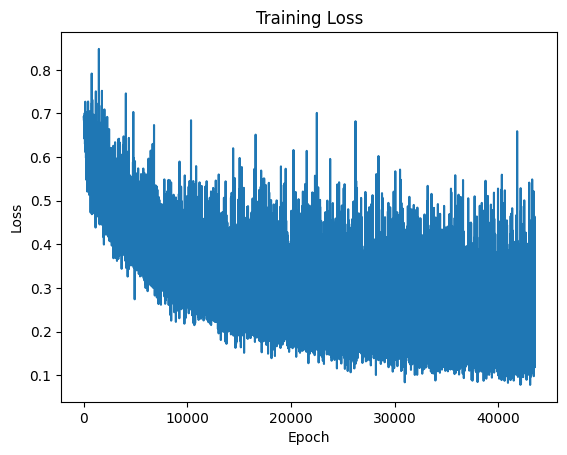

100%|██████████| 63/63 [00:02<00:00, 28.86it/s]


Time: 2.185229593999793
Accuracy: 0.9265
Precision: 0.9511677282377919
Recall: 0.8986960882647944
F1: 0.924187725631769
ROC-AUC: 0.9760687846190617


In [ ]:
import pandas as pd
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import kagglehub
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("nikhileswarkomati/suicide-watch")
data = pd.read_csv(dataset_path + "/Suicide_Detection.csv").sample(frac=0.375, random_state=SEED)
data["label"] = data["class"].astype("category").cat.codes

texts = data["text"].astype(str).tolist()
labels = data["label"].tolist()

def tokenize(text):
    return text.lower().split()

vocab = {}
for text in texts:
    for token in tokenize(text):
        if token not in vocab:
            vocab[token] = len(vocab)

vocab_size = len(vocab)
torch.save(vocab, "bow_space_vocab.pt")

def encode_binary(tokens):
    vec = torch.zeros(vocab_size)
    for t in tokens:
        idx = vocab.get(t)
        if idx is not None:
            vec[idx] = 1
    return vec

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        x = encode_binary(tokens)
        return x, self.labels[index]

def collate_fn(batch):
    seqs = torch.stack([item[0] for item in batch])
    labels = torch.tensor([item[1] for item in batch], dtype=torch.long)
    return seqs, labels

dataset = TextDataset(texts, labels)
train_size = int(0.8 * len(dataset))
train_dataset = torch.utils.data.Subset(dataset, range(0, train_size))
eval_dataset  = torch.utils.data.Subset(dataset, range(train_size, train_size + 2000))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
eval_loader  = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class bowmodel(nn.Module):
    def __init__(self, vocab, num_classes):
        super().__init__()
        self.lin = nn.Linear(vocab, num_classes)

    def forward(self, x):
        return self.lin(x)

model = bowmodel(vocab_size, 2).to(device)
optimizer = optim.Adam(model.parameters(), lr=2e-5)
loss_fn = nn.CrossEntropyLoss().to(device)
losses = []

for epoch in tqdm(range(20)):
    model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        loss = loss_fn(logits, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch: {epoch}. Average Loss: {avg_loss:.4f}")

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")
torch.save(model.state_dict(), "bow_suicide_classifier.pt")


In [ ]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("rvarun11/suicidal-ideation-reddit-dataset")
data = pd.read_csv(dataset_path + "/suicidal_ideation_reddit_annotated.csv")

data["text"] = data["usertext"].astype(str)
texts = data["text"].tolist()
labels = data["label"].astype(int).tolist()

indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

vocab = torch.load("bow_space_vocab.pt", map_location="cpu")
vocab_size = len(vocab)

def tokenize(text):
    return text.lower().split()

def encode_bow(tokens):
    vec = torch.zeros(vocab_size)
    for t in tokens:
        idx = vocab.get(t)
        if idx is not None and 0 <= idx < vocab_size:
            vec[idx] = 1
    return vec

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        x = encode_binary(tokens)
        y = torch.tensor(self.labels[index], dtype=torch.long)
        return x, y

def collate_fn(batch):
    xs = torch.stack([item[0] for item in batch])
    ys = torch.stack([item[1] for item in batch])
    return xs, ys

eval_dataset = TextDataset(texts, labels)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class bowmodel(torch.nn.Module):
    def __init__(self, vocab, num_classes):
        super().__init__()
        self.lin = torch.nn.Linear(vocab, num_classes)

    def forward(self, x):
        return self.lin(x)

model = bowmodel(vocab_size, 2).to(device)
model.load_state_dict(torch.load("bow_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 3.79M/3.79M [00:00<00:00, 5.66MB/s]

Extracting files...



100%|██████████| 63/63 [00:02<00:00, 27.14it/s]

Time: 2.3282905949999986
Accuracy: 0.8750
Precision: 0.8619133574007221
Recall: 0.9077946768060836
F1: 0.8842592592592593
ROC-AUC: 0.9262851751135068


In [ ]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mapping = {
    "non-suicide": 0,
    "suicide": 1
}
dataset_path = kagglehub.dataset_download("neelakshigupta/suicide-detection")
data = pd.read_csv(dataset_path + "/file1.csv")
data["text"] = data["text"]
data["Suicide"] = data["class"].map(mapping)
data = data.dropna(subset = ["text", "class"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
vocab = torch.load("bow_space_vocab.pt", map_location="cpu")
vocab_size = len(vocab)

def tokenize(text):
    return text.lower().split()

def encode_binary(tokens):
    vec = torch.zeros(vocab_size)
    for t in tokens:
        idx = vocab.get(t)
        if idx is not None and 0 <= idx < vocab_size:
            vec[idx] = 1
    return vec

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        x = encode_binary(tokens)
        y = torch.tensor(self.labels[index], dtype=torch.long)
        return x, y

def collate_fn(batch):
    xs = torch.stack([item[0] for item in batch])
    ys = torch.stack([item[1] for item in batch])
    return xs, ys

eval_dataset = TextDataset(texts, labels)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class bowmodel(torch.nn.Module):
    def __init__(self, vocab, num_classes):
        super().__init__()
        self.lin = torch.nn.Linear(vocab, num_classes)

    def forward(self, x):
        return self.lin(x)

model = bowmodel(vocab_size, 2).to(device)
model.load_state_dict(torch.load("bow_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 1.45M/1.45M [00:00<00:00, 2.61MB/s]

Extracting files...



100%|██████████| 63/63 [00:01<00:00, 39.65it/s]

Time: 1.5957416039991585
Accuracy: 0.8835
Precision: 0.96875
Recall: 0.7884028484231943
F1: 0.8693213684800898
ROC-AUC: 0.958249434086451


In [ ]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mapping = {
    "Not Suicide post": 0,
    "Potential Suicide post ": 1
}
dataset_path = kagglehub.dataset_download("aunanya875/suicidal-tweet-detection-dataset")
data = pd.read_csv(dataset_path + "/Suicide_Ideation_Dataset(Twitter-based).csv")
data["text"] = data["Tweet"]
data["Suicide"] = data["Suicide"].map(mapping)
data = data.dropna(subset=["Tweet", "Suicide"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
vocab = torch.load("bow_space_vocab.pt", map_location="cpu")
vocab_size = len(vocab)

def tokenize(text):
    return text.lower().split()

def encode_binary(tokens):
    vec = torch.zeros(vocab_size)
    for t in tokens:
        idx = vocab.get(t)
        if idx is not None and 0 <= idx < vocab_size:
            vec[idx] = 1
    return vec

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        x = encode_binary(tokens)
        y = torch.tensor(self.labels[index], dtype=torch.long)
        return x, y

def collate_fn(batch):
    xs = torch.stack([item[0] for item in batch])
    ys = torch.stack([item[1] for item in batch])
    return xs, ys

eval_dataset = TextDataset(texts, labels)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class bowmodel(torch.nn.Module):
    def __init__(self, vocab, num_classes):
        super().__init__()
        self.lin = torch.nn.Linear(vocab, num_classes)

    def forward(self, x):
        return self.lin(x)

model = bowmodel(vocab_size, 2).to(device)
model.load_state_dict(torch.load("bow_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 88.3k/88.3k [00:00<00:00, 717kB/s]

Extracting files...



100%|██████████| 56/56 [00:00<00:00, 67.07it/s]

Time: 0.841734625000754
Accuracy: 0.7748
Precision: 0.921311475409836
Recall: 0.4264036418816389
F1: 0.58298755186722
ROC-AUC: 0.8395019635218871


# Embedding

100%|██████████| 60.6M/60.6M [00:03<00:00, 16.1MB/s]

Extracting files...



  5%|▌         | 1/20 [00:10<03:18, 10.44s/it]

Epoch: 0. Average Loss: 0.5452


 10%|█         | 2/20 [00:20<03:03, 10.17s/it]

...

Epoch: 17. Average Loss: 0.1146


 95%|█████████▌| 19/20 [03:05<00:09,  9.69s/it]

Epoch: 18. Average Loss: 0.1095


100%|██████████| 20/20 [03:15<00:00,  9.77s/it]

Epoch: 19. Average Loss: 0.1047


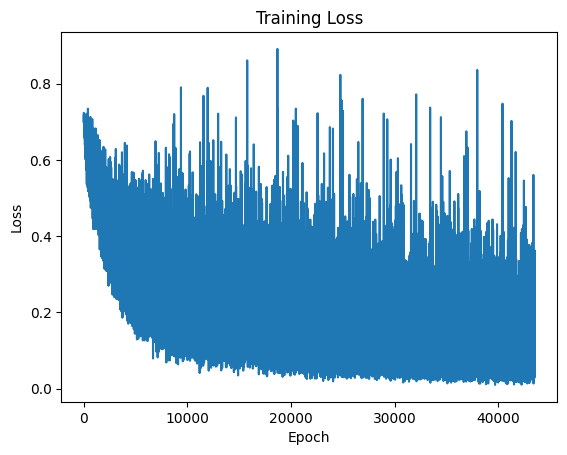

100%|██████████| 63/63 [00:00<00:00, 290.15it/s]


Time: 0.2193631220000043
Accuracy: 0.9265
Precision: 0.9360587002096437
Recall: 0.9121552604698672
F1: 0.9239524055871702
ROC-AUC: 0.9790227490323232


In [ ]:
import pandas as pd
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import kagglehub
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("nikhileswarkomati/suicide-watch")
data = pd.read_csv(dataset_path + "/Suicide_Detection.csv").sample(frac=0.375, random_state=0)
data["label"] = data["class"].astype("category").cat.codes

texts = data["text"].astype(str).tolist()
labels = data["label"].tolist()

def tokenize(text):
    return text.lower().split()

vocab = {}
for text in texts:
    for token in tokenize(text):
        if token not in vocab:
            vocab[token] = len(vocab)+1

vocab_size = len(vocab)+1
torch.save(vocab, "embedding_space_vocab.pt")
class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        ids = [vocab[t] for t in tokens if t in vocab][:self.max_length]
        if len(ids) < self.max_length:
            ids += [0] * (self.max_length - len(ids))
        return torch.tensor(ids, dtype=torch.long), self.labels[index]

def collate_fn(batch):
    seqs = torch.stack([item[0] for item in batch])
    labels = torch.tensor([item[1] for item in batch], dtype=torch.long)
    return seqs, labels

dataset = TextDataset(texts, labels)
train_size = int(0.8 * len(dataset))
train_dataset = torch.utils.data.Subset(dataset, range(0, train_size))
eval_dataset  = torch.utils.data.Subset(dataset, range(train_size, train_size + 2000))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
eval_loader  = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class embeddingmodel(nn.Module):
    def __init__(self, vocab, emb_dim, num_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim, padding_idx=0)
        self.lin = nn.Linear(emb_dim, num_classes)

    def forward(self, x):
        e = self.emb(x)
        m = e.mean(dim=1)
        return self.lin(m)

model = embeddingmodel(vocab_size, 128, 2).to(device)
optimizer = optim.Adam(model.parameters(), lr=2e-4)
loss_fn = nn.CrossEntropyLoss()
losses = []

for epoch in tqdm(range(20)):
    model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        loss = loss_fn(logits, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch: {epoch}. Average Loss: {avg_loss:.4f}")

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")
torch.save(model.state_dict(), "embedding_suicide_classifier.pt")


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("rvarun11/suicidal-ideation-reddit-dataset")
data = pd.read_csv(dataset_path + "/suicidal_ideation_reddit_annotated.csv")

data["text"] = data["usertext"].astype(str)
texts = data["text"].tolist()
labels = data["label"].astype(int).tolist()

indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

vocab = torch.load("embedding_space_vocab.pt", map_location="cpu")
vocab_size = len(vocab) + 1
pad_idx = 0
max_length = 128
emb_dim = 128

def tokenize(text):
    return text.lower().split()

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        ids = [vocab.get(t, 0) for t in tokens][:self.max_length]
        if len(ids) < self.max_length:
            ids += [pad_idx] * (self.max_length - len(ids))
        x = torch.tensor(ids, dtype=torch.long)
        y = torch.tensor(self.labels[index], dtype=torch.long)
        return x, y

def collate_fn(batch):
    xs = torch.stack([item[0] for item in batch])
    ys = torch.stack([item[1] for item in batch])
    return xs, ys

eval_dataset = TextDataset(texts, labels, max_length=max_length)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class embeddingmodel(nn.Module):
    def __init__(self, vocab, emb_dim, num_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim, padding_idx=pad_idx)
        self.lin = nn.Linear(emb_dim, num_classes)

    def forward(self, x):
        e = self.emb(x)
        m = e.mean(dim=1)
        return self.lin(m)

model = embeddingmodel(vocab_size, emb_dim, 2).to(device)
model.load_state_dict(torch.load("embedding_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 3.79M/3.79M [00:01<00:00, 2.94MB/s]

Extracting files...



100%|██████████| 63/63 [00:00<00:00, 387.14it/s]

Time: 0.1650682219999453
Accuracy: 0.8595
Precision: 0.8286445012787724
Recall: 0.9239543726235742
F1: 0.8737078651685394
ROC-AUC: 0.9107376345638607


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mapping = {
    "non-suicide": 0,
    "suicide": 1
}
dataset_path = kagglehub.dataset_download("neelakshigupta/suicide-detection")
data = pd.read_csv(dataset_path + "/file1.csv")
data["text"] = data["text"]
data["Suicide"] = data["class"].map(mapping)
data = data.dropna(subset = ["text", "class"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

vocab = torch.load("embedding_space_vocab.pt", map_location="cpu")
vocab_size = len(vocab) + 1
pad_idx = 0
max_length = 128
emb_dim = 128

def tokenize(text):
    return text.lower().split()

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        ids = [vocab.get(t, 0) for t in tokens][:self.max_length]
        if len(ids) < self.max_length:
            ids += [pad_idx] * (self.max_length - len(ids))
        x = torch.tensor(ids, dtype=torch.long)
        y = torch.tensor(self.labels[index], dtype=torch.long)
        return x, y

def collate_fn(batch):
    xs = torch.stack([item[0] for item in batch])
    ys = torch.stack([item[1] for item in batch])
    return xs, ys

eval_dataset = TextDataset(texts, labels, max_length=max_length)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class embeddingmodel(nn.Module):
    def __init__(self, vocab, emb_dim, num_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim, padding_idx=pad_idx)
        self.lin = nn.Linear(emb_dim, num_classes)

    def forward(self, x):
        e = self.emb(x)
        m = e.mean(dim=1)
        return self.lin(m)

model = embeddingmodel(vocab_size, emb_dim, 2).to(device)
model.load_state_dict(torch.load("embedding_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 1.45M/1.45M [00:01<00:00, 1.36MB/s]

Extracting files...



100%|██████████| 63/63 [00:00<00:00, 170.21it/s]

Time: 0.3723693160000039
Accuracy: 0.8760
Precision: 0.9542645241038319
Recall: 0.785350966429298
F1: 0.8616071428571429
ROC-AUC: 0.9479424553696019


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mapping = {
    "Not Suicide post": 0,
    "Potential Suicide post ": 1
}
dataset_path = kagglehub.dataset_download("aunanya875/suicidal-tweet-detection-dataset")
data = pd.read_csv(dataset_path + "/Suicide_Ideation_Dataset(Twitter-based).csv")
data["text"] = data["Tweet"]
data["Suicide"] = data["Suicide"].map(mapping)
data = data.dropna(subset=["Tweet", "Suicide"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

vocab = torch.load("embedding_space_vocab.pt", map_location="cpu")
vocab_size = len(vocab) + 1
pad_idx = 0
max_length = 128
emb_dim = 128

def tokenize(text):
    return text.lower().split()

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])
        ids = [vocab.get(t, 0) for t in tokens][:self.max_length]
        if len(ids) < self.max_length:
            ids += [pad_idx] * (self.max_length - len(ids))
        x = torch.tensor(ids, dtype=torch.long)
        y = torch.tensor(self.labels[index], dtype=torch.long)
        return x, y

def collate_fn(batch):
    xs = torch.stack([item[0] for item in batch])
    ys = torch.stack([item[1] for item in batch])
    return xs, ys

eval_dataset = TextDataset(texts, labels, max_length=max_length)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class embeddingmodel(nn.Module):
    def __init__(self, vocab, emb_dim, num_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim, padding_idx=pad_idx)
        self.lin = nn.Linear(emb_dim, num_classes)

    def forward(self, x):
        e = self.emb(x)
        m = e.mean(dim=1)
        return self.lin(m)

model = embeddingmodel(vocab_size, emb_dim, 2).to(device)
model.load_state_dict(torch.load("embedding_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 88.3k/88.3k [00:00<00:00, 377kB/s]

Extracting files...



100%|██████████| 56/56 [00:00<00:00, 644.07it/s]

Time: 0.08926960100006909
Accuracy: 0.7731
Precision: 0.8871951219512195
Recall: 0.44157814871016693
F1: 0.5896656534954408
ROC-AUC: 0.8060560567305541
